# X-ray projection -- Parallel and Radial

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch08/ch08-01.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Parallel-Ray Projection

### Static image with `matplotlib`

In [1]:
import matplotlib.pyplot as plt

%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

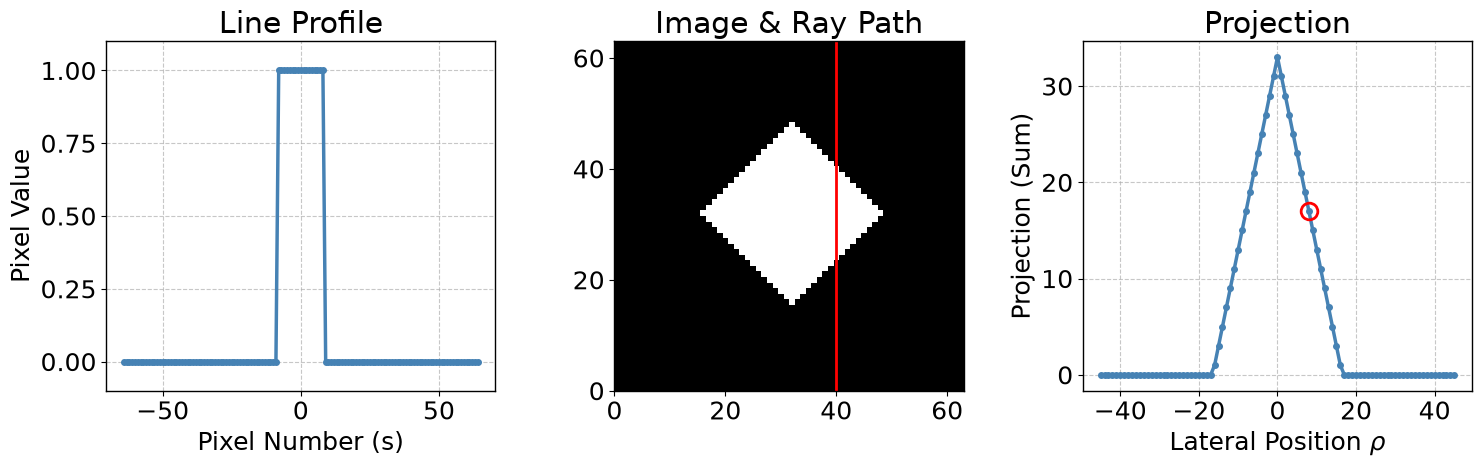

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# --- 1. Define Image Parameters ---
dims = 64
cx, cy = dims / 2, dims / 2

# Create coordinate grids (y represents rows, x represents columns)
y, x = np.mgrid[0:dims, 0:dims]

# --- 2. Create Object Masks ---
# 1: Disk (Radius 16)
disk = ((x - cx)**2 + (y - cy)**2 <= 16**2).astype(float)
# 2: Diamond (Radius 16)
diamond = (np.abs(x - cx) + np.abs(y - cy) <= 16).astype(float)
# 3: Square / Box (Radius 16)
box = ((np.abs(x - cx) <= 16) & (np.abs(y - cy) <= 16)).astype(float)
# 4: Diagonal Line
diag = np.zeros((dims, dims))
np.fill_diagonal(diag, 1); np.fill_diagonal(diag[1:], 1); np.fill_diagonal(diag[:, 1:], 1)
# 5: Cross
cross = np.zeros((dims, dims))
cross[int(cy)-16:int(cy)+17, int(cx)] = 1
cross[int(cy), int(cx)-16:int(cx)+17] = 1

objectlist = [disk, diamond, box, diag, cross]

# Select Diamond. Note: Python uses 0-based indexing, 
# so Mathematica's objectlist[[2]] becomes objectlist[1]
g1 = objectlist[1] 

# --- 3. Set Calculation Parameters ---
theta = 0.0     # Angle of projection
rho_val = 8.0   # Current Lateral Position (Change this to simulate slider)

# Calculate the bounds for rho (-dims*sqrt(2)/2 to dims*sqrt(2)/2)
rho_max = int(np.round(dims * np.sqrt(2.0) / 2))
rhos = np.arange(-rho_max, rho_max + 1)

# --- 4. Projection Functions ---
def get_ray_profile(image, rho, theta):
    s = np.arange(-dims, dims + 1)
    
    # Parameterized line equations (exactly matching the Mathematica snippet)
    ray_x = rho * np.cos(theta) - s * np.sin(theta) + dims / 2
    ray_y = rho * np.sin(theta) + s * np.cos(theta) + dims / 2
    
    # Sample the image along the ray using nearest-neighbor (order=0)
    # Note: image array indexing is [row, col] which corresponds to [y, x]
    profile = map_coordinates(image, [ray_y, ray_x], order=0, cval=0.0)
    return profile, ray_x, ray_y

def get_total_projection(image, theta):
    totals = []
    for r in rhos:
        profile, _, _ = get_ray_profile(image, r, theta)
        totals.append(np.sum(profile))
    return np.array(totals)

# Execute the math for the chosen rho and the overall projection
profile_rho, current_ray_x, current_ray_y = get_ray_profile(g1, rho_val, theta)
total_proj_0 = get_total_projection(g1, theta)


# --- 5. Plotting (Replicating Mathematica's GraphicsRow) ---
fig1, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Line Profile
s_vals = np.arange(-dims, dims + 1)
axes[0].plot(s_vals, profile_rho, marker='o', linestyle='-', color='steelblue', markersize=4)
axes[0].set_title('Line Profile')
axes[0].set_xlabel('Pixel Number (s)')
axes[0].set_ylabel('Pixel Value')
axes[0].set_ylim([-0.1, 1.1])
axes[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Image and Ray Path
# origin='lower' forces the image to map Cartesian-style, matching Mathematica
axes[1].imshow(g1, cmap='gray', origin='lower')
axes[1].plot(current_ray_x, current_ray_y, 'r-', linewidth=2)
axes[1].set_title('Image & Ray Path')
axes[1].set_xlim([0, dims-1])
axes[1].set_ylim([0, dims-1])

# Plot 3: Total Projection
axes[2].plot(rhos, total_proj_0, marker='o', linestyle='-', color='steelblue', markersize=4)

# Highlight the current rho point with an empty Red Circle
rho_idx = np.where(rhos == rho_val)[0][0]
axes[2].plot(rhos[rho_idx], total_proj_0[rho_idx], marker='o', color='red', 
             markersize=12, fillstyle='none', markeredgewidth=2)

axes[2].set_title('Projection')
axes[2].set_xlabel(r'Lateral Position $\rho$')
axes[2].set_ylabel('Projection (Sum)')
axes[2].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Make interactive with `ipywidgets`

In [3]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
import ipywidgets as widgets
from ipywidgets import interact

# --- 1. Define Image Parameters ---
dims2 = 64
cx2, cy2 = dims2 / 2, dims2 / 2

# Create coordinate grids (y2 represents rows, x2 represents columns)
y2, x2 = np.mgrid[0:dims2, 0:dims2]

# --- 2. Create Object Masks ---
# 1: Disk (Radius 16)
disk2 = ((x2 - cx2)**2 + (y2 - cy2)**2 <= 16**2).astype(float)
# 2: Diamond (Radius 16)
diamond2 = (np.abs(x2 - cx2) + np.abs(y2 - cy2) <= 16).astype(float)
# 3: Square / Box (Radius 16)
box2 = ((np.abs(x2 - cx2) <= 16) & (np.abs(y2 - cy2) <= 16)).astype(float)
# 4: Diagonal Line
diag2 = np.zeros((dims2, dims2))
np.fill_diagonal(diag2, 1); np.fill_diagonal(diag2[1:], 1); np.fill_diagonal(diag2[:, 1:], 1)
# 5: Cross
cross2 = np.zeros((dims2, dims2))
cross2[int(cy2)-16:int(cy2)+17, int(cx2)] = 1
cross2[int(cy2), int(cx2)-16:int(cx2)+17] = 1

# Store shapes in a dictionary for the Dropdown menu
shapes_dict = {
    'Disk': disk2,
    'Diamond': diamond2,
    'Square': box2,
    'Diagonal': diag2,
    'Cross': cross2
}

# --- 3. Set Calculation Parameters ---
theta2 = 0.0     # Angle of projection

# Calculate the bounds for rho (-dims2*sqrt(2)/2 to dims2*sqrt(2)/2)
rho_max2 = int(np.round(dims2 * np.sqrt(2.0) / 2))
rhos2 = np.arange(-rho_max2, rho_max2 + 1)

# --- 4. Projection Functions ---
def get_ray_profile2(image, rho, theta2):
    s = np.arange(-dims2, dims2 + 1)
    
    # Parameterized line equations
    ray_x = rho * np.cos(theta2) - s * np.sin(theta2) + dims2 / 2
    ray_y = rho * np.sin(theta2) + s * np.cos(theta2) + dims2 / 2
    
    # Sample the image along the ray using nearest-neighbor (order=0)
    profile = map_coordinates(image, [ray_y, ray_x], order=0, cval=0.0)
    return profile, ray_x, ray_y

def get_total_projection2(image, theta2):
    totals = []
    for r in rhos2:
        profile, _, _ = get_ray_profile2(image, r, theta2)
        totals.append(np.sum(profile))
    return np.array(totals)

# --- 5. Interactive Plotting Function ---
def update_plot(shape_name, rho_val):
    # Retrieve the selected shape
    g1 = shapes_dict[shape_name]
    
    # Execute the math for the chosen rho and the overall projection
    profile_rho, current_ray_x, current_ray_y = get_ray_profile2(g1, rho_val, theta2)
    total_proj_0 = get_total_projection2(g1, theta2)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Plot 1: Line Profile
    s_vals = np.arange(-dims2, dims2 + 1)
    axes[0].plot(s_vals, profile_rho, marker='o', linestyle='-', color='steelblue', markersize=4)
    axes[0].set_title('Line Profile')
    axes[0].set_xlabel('Pixel Number (s)')
    axes[0].set_ylabel('Pixel Value')
    axes[0].set_ylim([-0.1, 1.1])
    axes[0].grid(True, linestyle='--', alpha=0.7)

    # Plot 2: Image and Ray Path
    axes[1].imshow(g1, cmap='gray', origin='lower')
    axes[1].plot(current_ray_x, current_ray_y, 'r-', linewidth=2)
    axes[1].set_title(f'Image ({shape_name}) & Ray Path')
    axes[1].set_xlim([0, dims2-1])
    axes[1].set_ylim([0, dims2-1])

    # Plot 3: Total Projection
    axes[2].plot(rhos2, total_proj_0, marker='o', linestyle='-', color='steelblue', markersize=4)

    # Highlight the current rho point with an empty Red Circle
    rho_idx = np.where(rhos2 == rho_val)[0][0]
    axes[2].plot(rhos2[rho_idx], total_proj_0[rho_idx], marker='o', color='red', 
                 markersize=12, fillstyle='none', markeredgewidth=2)

    axes[2].set_title('Projection')
    axes[2].set_xlabel(r'Lateral Position $\rho$')
    axes[2].set_ylabel('Projection (Sum)')
    axes[2].grid(True, linestyle='--', alpha=0.7)
    
    # Keep the bottom y2-limit fixed, but allow the top to autoscale based on the shape
    axes[2].set_ylim(bottom=-1)

    plt.tight_layout()
    plt.show()

# --- 6. Set up ipywidgets UI ---
shape_dropdown = widgets.Dropdown(
    options=list(shapes_dict.keys()),
    value='Diamond',
    description='Shape:'
)

rho_slider = widgets.IntSlider(
    value=8,
    min=-rho_max2,
    max=rho_max2,
    step=1,
    description='Ray Pos (\u03C1):', # Uses Unicode for rho
    layout=widgets.Layout(width='400px')
)

# Launch the interactive widget
interact(update_plot, shape_name=shape_dropdown, rho_val=rho_slider);

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch08/ch08-01-parallel_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch08/ch08-01.html) (direct link: [ch08-01-parallel_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch08/ch08-01-parallel_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.

## Radial Projection

### Static image with `matplotlib`

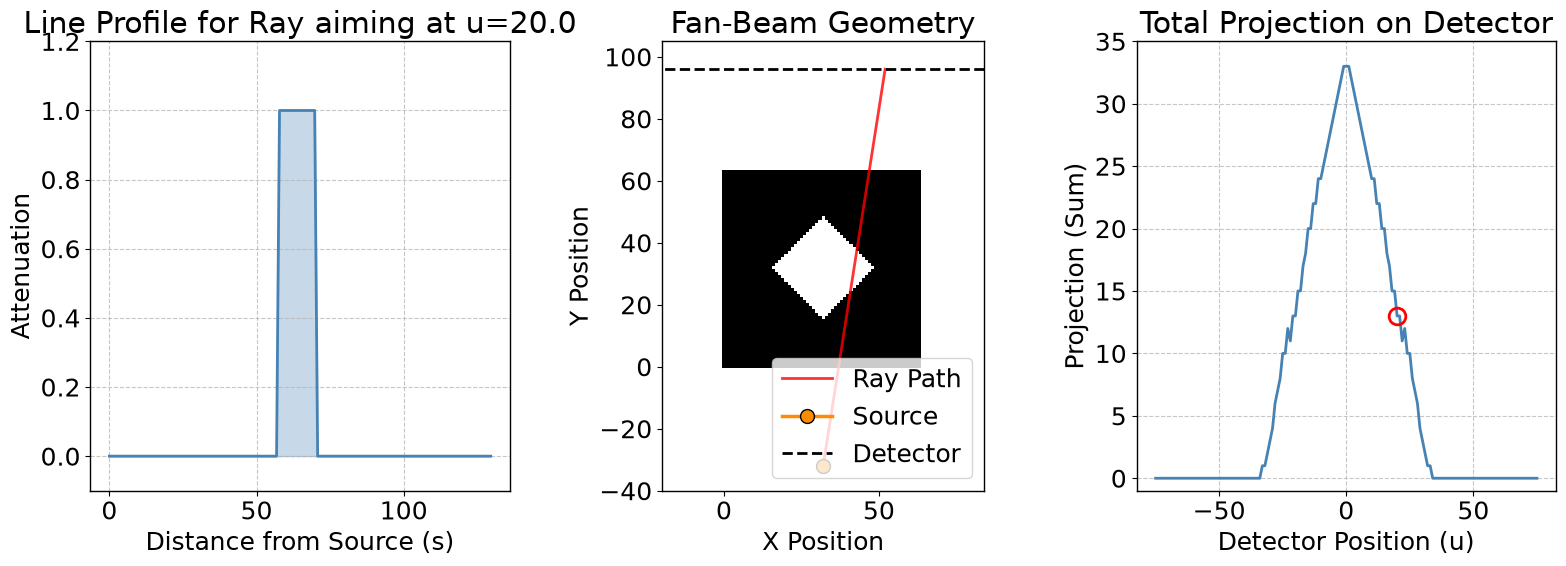

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates

# --- 1. Simulation Parameters (Radial Geometry) ---
dims3 = 64
cx3, cy3 = dims3 / 2, dims3 / 2

# Point Source Location (Below the object)
Sx = cx3
Sy = -32.0

# Detector Plane Location (Above the object)
Dy = 96.0
u_max = 75

# Fixed detector position to visualize (Simulates the slider)
u_val = 20.0 

u_vals = np.arange(-u_max, u_max + 1)

# --- 2. Create Object Mask (Diamond) ---
y3, x3 = np.mgrid[0:dims3, 0:dims3]
img = (np.abs(x3 - cx3) + np.abs(y3 - cy3) <= 16).astype(float)

# --- 3. Radial Ray Tracing Function ---
def get_ray_profile_radial(image, u):
    # Vector from Source to Detector Pixel
    Dx = cx3 + u
    L = np.sqrt((Dx - Sx)**2 + (Dy - Sy)**2)
    
    # Normalized direction vector
    vx = (Dx - Sx) / L
    vy = (Dy - Sy) / L
    
    # March along the ray from Source to Detector (1 unit per step)
    s_vals = np.linspace(0, L, int(np.ceil(L)) + 1)
    
    ray_x = Sx + s_vals * vx
    ray_y = Sy + s_vals * vy
    
    # Sample the image along the ray using nearest-neighbor (order=0)
    # Note: image array indexing is [row, col] which corresponds to [y3, x3]
    profile = map_coordinates(image, [ray_y, ray_x], order=0, cval=0.0)
    
    return profile, ray_x, ray_y, s_vals

# --- 4. Calculate Projections ---
# Total projection for all detector pixels
totals = []
for u in u_vals:
    prof, _, _, _ = get_ray_profile_radial(img, u)
    totals.append(np.sum(prof))
totals = np.array(totals)

# Profile for the currently selected ray
profile_u, current_ray_x3, current_ray_y3, s_vals_ray = get_ray_profile_radial(img, u_val)


# --- 5. Plotting ---
fig2, axes3 = plt.subplots(1, 3, figsize=(16, 6))

# Plot 1: Line Profile along the single ray
axes3[0].plot(s_vals_ray, profile_u, color='steelblue', linewidth=2)
axes3[0].fill_between(s_vals_ray, profile_u, color='steelblue', alpha=0.3) # Shaded area
axes3[0].set_title(f'Line Profile for Ray aiming at u={u_val}')
axes3[0].set_xlabel('Distance from Source (s)')
axes3[0].set_ylabel('Attenuation')
axes3[0].set_ylim([-0.1, 1.2])
axes3[0].grid(True, linestyle='--', alpha=0.7)

# Plot 2: Image and Radial Geometry
axes3[1].imshow(img, cmap='gray', origin='lower')
axes3[1].plot(current_ray_x3, current_ray_y3, 'r-', linewidth=2, alpha=0.8, label='Ray Path')
axes3[1].plot([Sx], [Sy], marker='o', color='darkorange', markersize=10, markeredgecolor='black', label='Source')
axes3[1].plot([cx3 - u_max, cx3 + u_max], [Dy, Dy], 'k--', linewidth=2, label='Detector')

axes3[1].set_title('Fan-Beam Geometry')
axes3[1].set_xlim([-20, 84])
axes3[1].set_ylim([-40, 105])  # Expanded Y-axis to show Source and Detector
axes3[1].set_xlabel('X Position')
axes3[1].set_ylabel('Y Position')
axes3[1].legend(loc='lower right')

# Plot 3: Total Projection Array
axes3[2].plot(u_vals, totals, color='steelblue', linewidth=2)

# Highlight the current u point with an empty Red Circle
u_idx = np.where(u_vals == u_val)[0][0]
axes3[2].plot(u_vals[u_idx], totals[u_idx], marker='o', color='red', 
             markersize=12, fillstyle='none', markeredgewidth=2)

axes3[2].set_title('Total Projection on Detector')
axes3[2].set_xlabel('Detector Position (u)')
axes3[2].set_ylabel('Projection (Sum)')
axes3[2].set_ylim([-1, np.max(totals) + 2])
axes3[2].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Make interactive with `ipywidgets`

In [6]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
import ipywidgets as widgets
from ipywidgets import interact

# --- 1. Simulation Parameters (Radial Geometry) ---
dims4 = 64
cx4, cy4 = dims4 / 2, dims4 / 2

# Point Source Location (Below the object)
Sx4 = cx4
Sy4 = -32.0

# Detector Plane Location (Above the object)
Dy4 = 96.0
u_max4 = 75
u_vals4 = np.arange(-u_max4, u_max4 + 1)

# --- 2. Create Object Masks ---
y4, x4 = np.mgrid[0:dims4, 0:dims4]

disk4 = ((x4 - cx4)**2 + (y4 - cy4)**2 <= 16**2).astype(float)
diamond4 = (np.abs(x4 - cx4) + np.abs(y4 - cy4) <= 16).astype(float)
box4 = ((np.abs(x4 - cx4) <= 16) & (np.abs(y4 - cy4) <= 16)).astype(float)
diag4 = np.zeros((dims4, dims4))
np.fill_diagonal(diag4, 1); np.fill_diagonal(diag4[1:], 1); np.fill_diagonal(diag4[:, 1:], 1)
cross4 = np.zeros((dims4, dims4))
cross4[int(cy4)-16:int(cy4)+17, int(cx4)] = 1
cross4[int(cy4), int(cx4)-16:int(cx4)+17] = 1

shapes_dict_radial = {
    'Disk': disk4, 'Diamond': diamond4, 'Square': box4, 
    'Diagonal': diag4, 'Cross': cross4
}

# --- 3. Radial Ray Tracing Function ---
def get_ray_profile_radial4(image, u):
    # Vector from Source to Detector Pixel
    Dx = cx4 + u
    L = np.sqrt((Dx - Sx4)**2 + (Dy4 - Sy4)**2)
    
    # Normalized direction vector
    vx = (Dx - Sx4) / L
    vy = (Dy4 - Sy4) / L
    
    # March along the ray from Source to Detector
    s_vals = np.linspace(0, L, int(np.ceil(L)) + 1)
    
    ray_x = Sx4 + s_vals * vx
    ray_y = Sy4 + s_vals * vy
    
    # Sample the image along the ray using nearest-neighbor
    profile = map_coordinates(image, [ray_y, ray_x], order=0, cval=0.0)
    
    return profile, ray_x, ray_y, s_vals

# --- 4. Cache Total Projections (For smooth slider performance) ---
# We calculate the full projection curves for all shapes right away 
# so the slider doesn't lag when you drag it.
cached_totals = {}
for name, img in shapes_dict_radial.items():
    tots = []
    for u in u_vals4:
        prof4, _, _, _ = get_ray_profile_radial4(img, u)
        tots.append(np.sum(prof4))
    cached_totals[name] = np.array(tots)

# --- 5. Interactive Plotting Function ---
def update_plot4(shape_name, u_val):
    img = shapes_dict_radial[shape_name]
    totals = cached_totals[shape_name]
    
    # Calculate physics for the single requested ray
    profile_u, current_ray_x3, current_ray_y3, s_vals_ray = get_ray_profile_radial4(img, u_val)

    # Initialize Plot
    fig, axes3 = plt.subplots(1, 3, figsize=(16, 5))

    # Plot 1: Line Profile along the single ray
    axes3[0].plot(s_vals_ray, profile_u, color='steelblue', linewidth=2)
    axes3[0].fill_between(s_vals_ray, profile_u, color='steelblue', alpha=0.3)
    axes3[0].set_title(f'Line Profile (u = {u_val})')
    axes3[0].set_xlabel('Distance from Source (s)')
    axes3[0].set_ylabel('Attenuation')
    axes3[0].set_ylim([-0.1, 1.2])
    axes3[0].grid(True, linestyle='--', alpha=0.7)

    # Plot 2: Image and Radial Geometry
    axes3[1].imshow(img, cmap='gray', origin='lower')
    axes3[1].plot(current_ray_x3, current_ray_y3, 'r-', linewidth=2, alpha=0.8, label='Ray Path')
    axes3[1].plot([Sx4], [Sy4], marker='o', color='darkorange', markersize=10, markeredgecolor='black', label='Source')
    axes3[1].plot([cx4 - u_max4, cx4 + u_max4], [Dy4, Dy4], 'k--', linewidth=2, label='Detector')

    axes3[1].set_title('Fan-Beam Geometry')
    axes3[1].set_xlim([-20, 84])
    axes3[1].set_ylim([-40, 105])  # Expanded Y-axis to show Source and Detector
    axes3[1].set_xlabel('X Position')
    axes3[1].set_ylabel('Y Position')
    axes3[1].legend(loc='lower right')

    # Plot 3: Total Projection Array
    axes3[2].plot(u_vals4, totals, color='steelblue', linewidth=2)

    # Highlight the current u point with an empty Red Circle
    u_idx = np.where(u_vals4 == u_val)[0][0]
    axes3[2].plot(u_vals4[u_idx], totals[u_idx], marker='o', color='red', 
                 markersize=12, fillstyle='none', markeredgewidth=2)

    axes3[2].set_title('Total Projection on Detector')
    axes3[2].set_xlabel('Detector Position (u)')
    axes3[2].set_ylabel('Projection (Sum)')
    axes3[2].set_ylim([-1, np.max(totals) + 2])
    axes3[2].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show() # Crucial for clean interactive updates in VS Code

# --- 6. Set up ipywidgets UI ---
shape_dropdown4 = widgets.Dropdown(
    options=list(shapes_dict_radial.keys()),
    value='Diamond',
    description='Shape:'
)

u_slider = widgets.IntSlider(
    value=0,
    min=-u_max4,
    max=u_max4,
    step=1,
    description='Detector (u):',
    layout=widgets.Layout(width='400px')
)

# Launch the interactive widget
interact(update_plot4, shape_name=shape_dropdown4, u_val=u_slider);

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch08/ch08-01-radial_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch08/ch08-01.html) (direct link: [ch08-01-radial_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch08/ch08-01-radial_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.